# CM laser calibration v4: alignment → space charge → static, in dφ (v5 + v6 scans, 2026-10-22)
K0s runs take ~10 h, so the calibration has to be right on the laser first. Order:
1. **Alignment** of the CM truth to the pad plane (field off: no E×B), checked against the K0s balance of three corrections.
2. **Space charge** from the GEM-current differences between beam blocks (truth, static and alignment cancel);
   **2c (new)**: does the kink or b change with the luminosity?
3. **Static** at 795xx against the fully aligned truth, with the space charge fixed. **3c (new)**: the joint fit (dφ
   flat + R² = 0 + pointing = 0 + flat module steps at once) and its QA. **3d (new)**: the v6 frames test (m = 120
   frame maps, radial smoothing, frame charge) on the sector edges with beam.
4. **The static per run.**
5. **Final** comparisons with the CDB, nothing removed.
6. **Summary**, and the v7 scan (submitted) that should settle the space charge.

What a TPC-only track keeps of RΔφ(R) = a + bR + cR² + … over 30–76 cm: the R² sagitta (momentum, charge-odd), the
shape beyond the quadratic (resolution), and its pointing (quadratic extrapolated to R = 0). Offset and slope (shift,
rotation) are absorbed. Sector edges (±6°) are excluded everywhere; φ averages are weighted with the K0s-daughter φ distribution.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '/home/yoren/bnl/ROOT/install/lib')
import numpy as np, matplotlib.pyplot as plt
import cmplots as c, truthalign as ta, alignqa as aq, scdiff as sd, scdI_bigscan as sb, calib as cb, v5ana as v, slidestyle
plt.rcParams['figure.dpi'] = 80
plt.rcParams.update({'font.size': 14, 'axes.titlesize': 15, 'axes.labelsize': 15, 'legend.fontsize': 11,
                     'xtick.labelsize': 13, 'ytick.labelsize': 13, 'figure.titlesize': 16})
def show(*figs):
    for f in figs:
        display(slidestyle.restyle(f))
    plt.close('all')
ta.correct_truth()

{0: array([-2.02877286, -0.60458442,  0.35802086]),
 1: array([-2.9392519 , -0.34088598,  0.06488564])}

**Where the data come from.** Laser images of the CM stripes in every run (raw clusters from the pad DSTs, re-clustered
and matched to the CM stripe pattern in our condor jobs, local ideal TPC coordinates, no tracking alignment – the CDB
TPC alignment is all zero anyway). Each configuration (static model × space-charge map × keff) corrects the same raw
clusters with PHGarfield; the corrected clusters are compared with the CM truth (stripe positions), which is aligned to
the pad plane with field off (Section 1). Runs: field off 78242, no beam 75073 / 83319, beam 795xx (11 blocks, I 1.8–2.7 µA)
and 80892 / 81558 (6 blocks, I 5.4–7.0 µA).

**Rules used from here on (v3).**
- **Comparisons**: dφ [mrad] vs the aligned truth, **nothing removed** (a rotation that is fine at the CM can change with
  z; a constant RΔφ is a sideways shift of the tracks).
- **Fits**: dφ with only a constant (rotation) free; the target is dφ flat in R.

## 1. Alignment: CM truth → pad plane
### 1a. Field off: the R shape a rigid alignment leaves
Rigid CM alignment from field off (S −2.03 mrad, (−0.61, +0.36) mm; N −2.94 mrad, (−0.34, +0.07) mm) plus 36 pad-module
offsets with their ring means removed. Without B there is no E×B: what remains is geometry.

Welcome to JupyROOT 6.30/06


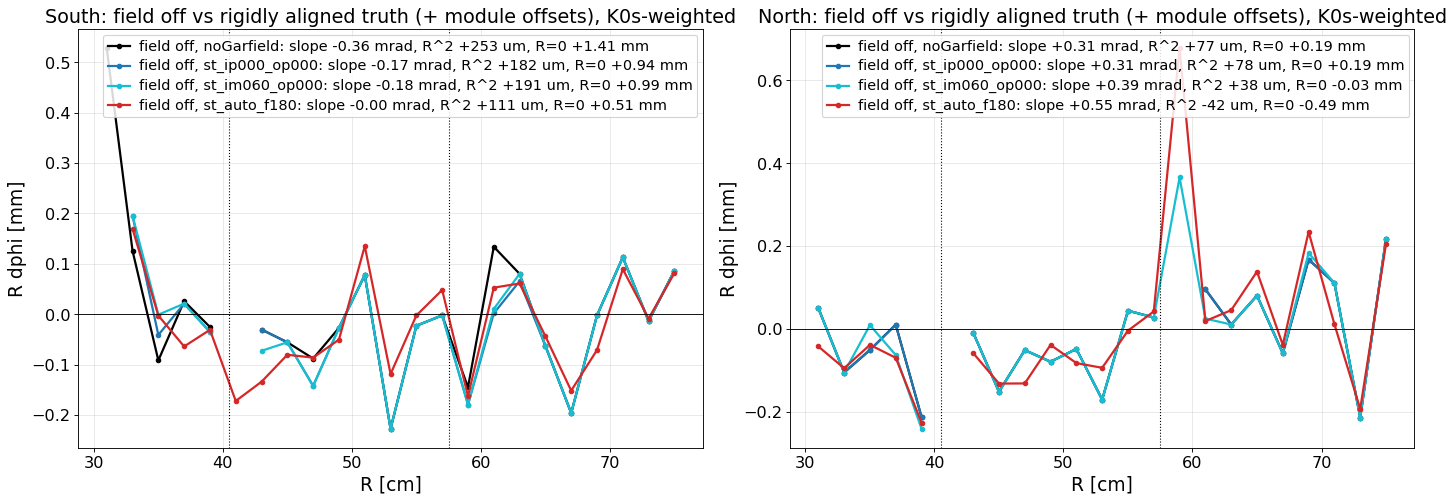

In [2]:
show(aq.fig_zf_alignment())

South +110 … +250 µm, North −40 … +80 µm of R² (range = the field-off correction used). The **full alignment** used from
here on subtracts, from raw field off (no PHGarfield correction: without B nothing moves in RΔφ), the 72 module
offsets and one common fine R profile (2 cm bins, φ-averaged) – it closes exactly in the φ average.

### 1a'. What the alignment is, step by step, and its values
1. **Rigid** CM → pad fit per side on field off, RΔφ only, sector edges excluded: rotation, dx, dy.
2. **72 pad modules** (12 sectors × R1/R2/R3 × 2 sides): median RΔφ per module after the rigid fit, ring mean removed.
3. **Common fine R profile**: median field-off RΔφ per 2 cm in R after steps 1–2 (φ-averaged): the stripe-row
   pattern (±0.2 mm) and the sharp inner-R1 rise in South (+0.6 mm at 31 cm). A coarser sector × 4 cm map (shown for
   its structure) averages that rise away and does not close (R² +157 / +85 µm left).

rigid CM -> pad alignment (field off 78242):
   South: rotation -2.03 mrad, dx -0.60 mm, dy +0.36 mm
   North: rotation -2.94 mrad, dx -0.34 mm, dy +0.06 mm


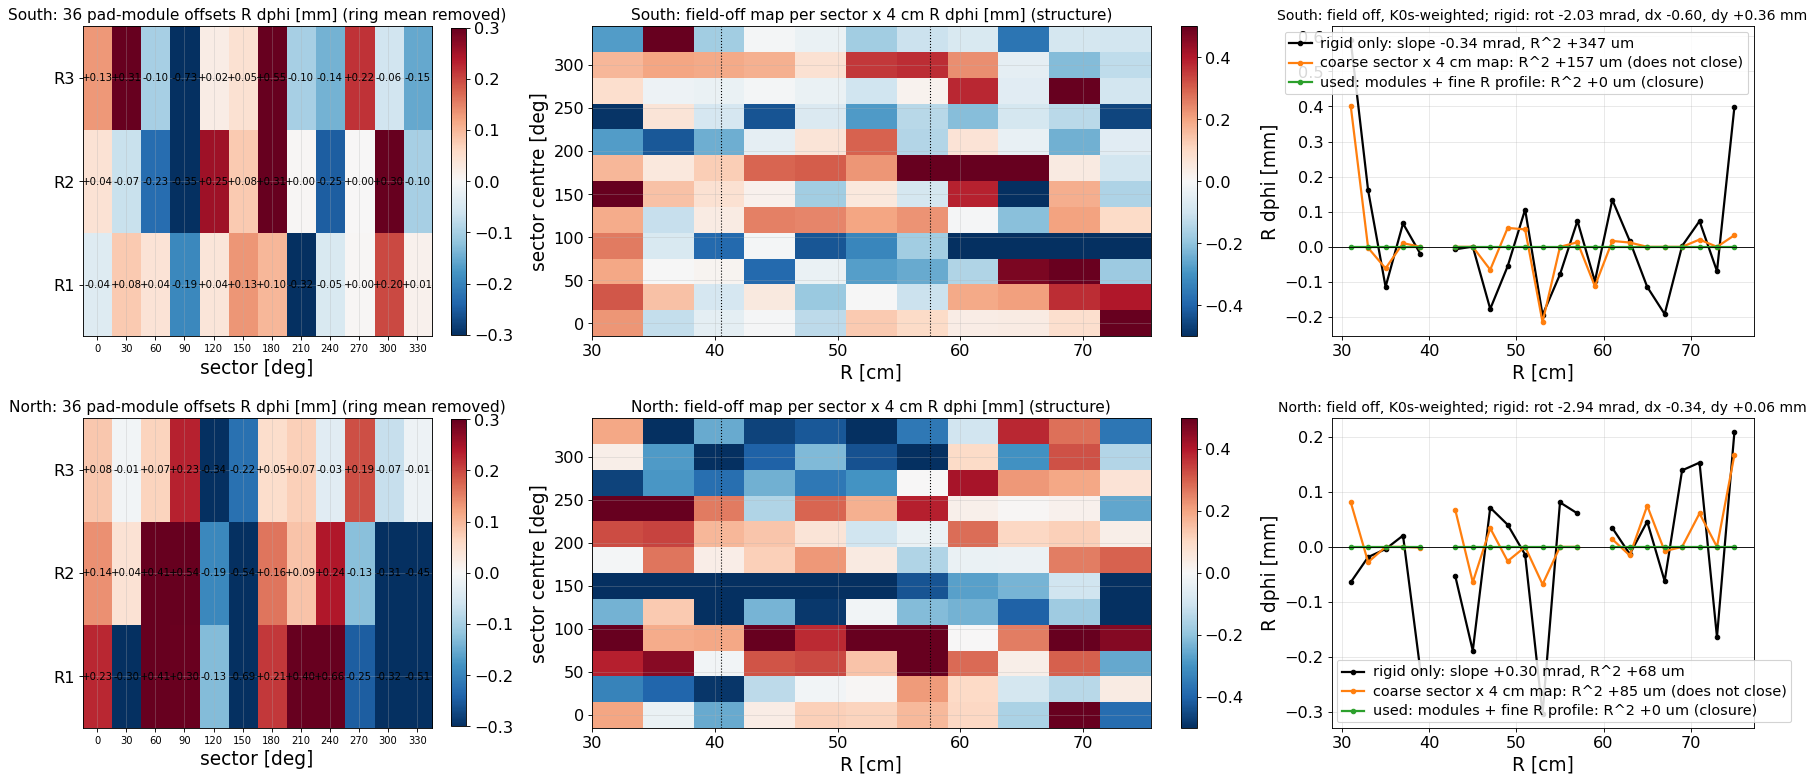

In [3]:
print('rigid CM -> pad alignment (field off 78242):')
for s, (rot, dx, dy) in cb.alignment_values().items():
    print(f"   {c.SIDES[s]:5s}: rotation {rot:+.2f} mrad, dx {dx:+.2f} mm, dy {dy:+.2f} mm")
show(cb.fig_alignment())

**Applying it at the pad plane.** Field off measures the CM pattern relative to the pads; it cannot tell which one moved.
If the CM stripes are where the drawing puts them, the 72 module offsets (up to ±0.3 mm) are pad-module positions and
can be applied to the clusters in local coordinates like a module alignment; the within-module stripe-row pattern
(±0.2 mm, period ~4 cm) looks like CM / pad-row geometry and should stay with the truth.

### 1b. Check against the tracks: K0s balance vs laser R² (795xx)
K0s: (⟨1/pT⁻⟩ − ⟨1/pT⁺⟩)/2 × 11.1 mm, cut03, mass 0.48–0.515 for every correction.

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/alignqa.py:486: RuntimeWarning: Mean of empty slice
  return dec(np.nanmean([wprof(x) for x in xs], axis=0), ta.PRC)


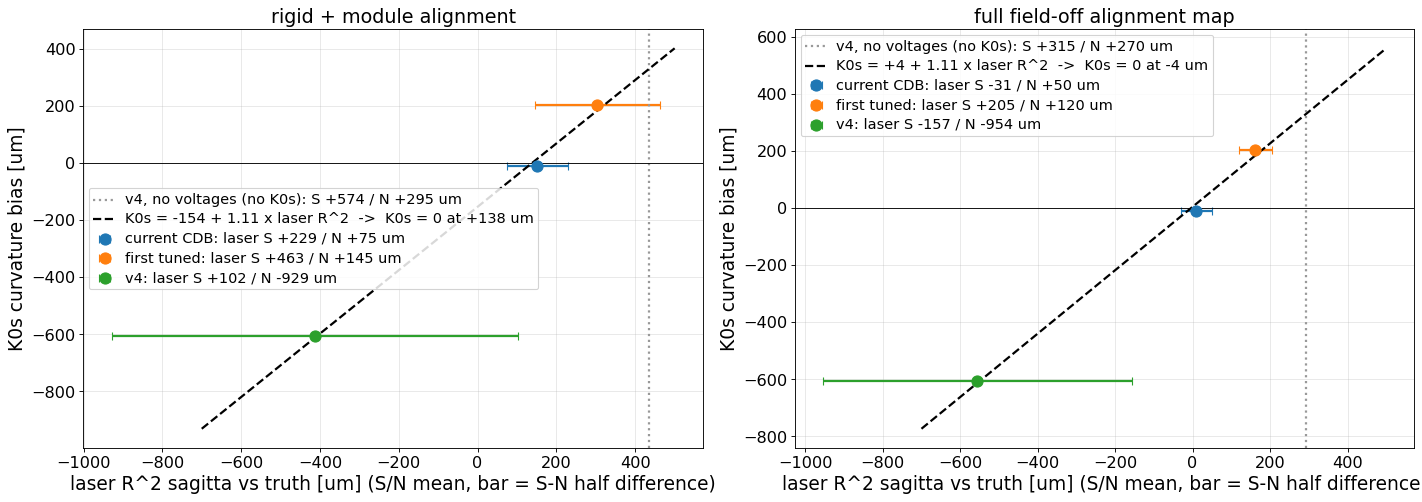

In [4]:
show(aq.fig_k0s_calibration())

With the full alignment: **K0s = +4 + 1.11 × laser R²** (residuals ≤ 25 µm, slope ≈ 1 as it must be): **K0s balance
0 ↔ laser R² ≈ 0** – a correction that matches the aligned CM truth gives balanced K0s. With only the rigid alignment
the zero was at +138 µm; with a PHGarfield-corrected field off as reference it is at +141 µm: the field-off R shape left
in the truth is why "better to the CM" made the tracks worse. (A 17 % N⁻/N⁺ at 2 GeV,
first tuned vs CDB, is ≈ 210 µm of sagitta: the falling spectrum amplifies it.)

### 1c. How good is the CDB, and is it kinky?

In [5]:
for s in (0, 1):
    d = cb.describe(cb.resid('cdb', s))
    print(f"CDB {c.SIDES[s]:5s}: R^2 {d['R2']:+5.0f} um, beyond-quad {d['beyond_quad']*1000:4.0f} um, steps at 40.5 / 57.5 cm {d['step1']:+.2f} / {d['step2']:+.2f} mm, pointing {d['pointing']:+.2f} mm")

CDB South: R^2   -31 um, beyond-quad  195 um, steps at 40.5 / 57.5 cm -0.17 / +0.28 mm, pointing +0.41 mm
CDB North: R^2   +50 um, beyond-quad  106 um, steps at 40.5 / 57.5 cm -0.31 / -0.13 mm, pointing +1.71 mm


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/calib.py:29: RuntimeWarning: Mean of empty slice
  _cache[k] = np.nanmean([aq.wprof(aq.full_aligned(r, ta.v4_tag(b, tag), s)) for r, b in aq.blocks(runs)], axis=0)


The CDB is on target within ±50 µm (South −31, North +50 µm; target 0) and **not kinky**: module-boundary steps
≤ 0.31 mm, beyond-quadratic 0.11–0.20 mm.

## 2. Space charge from ΔI_GEM (v5 scan; truth, static and alignment cancel)
Per CM stripe the corrected position is fitted linearly vs the block GEM current; the slope with a space-charge map is
what the map misses per µA. Converted to dφ; only a constant dφ per µA (a rotation growing with the current) is free.
Clean sets: **South** within 795xx, within 80892 + 81558, 79516 vs 80892 / 81558; **North** within 795xx only (its static
moves between runs, even between 80892 and 81558).

### 2a. keff vs the GEM current

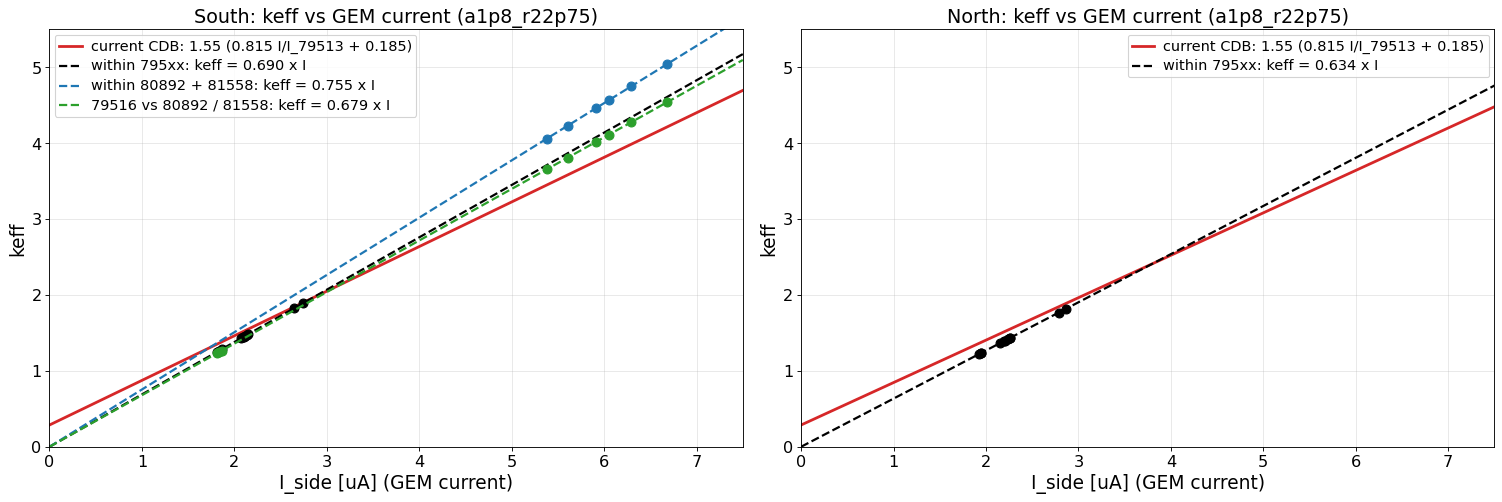

In [6]:
show(v.fig_keff_vs_I())

In [7]:
for s in (0, 1):
    print(c.SIDES[s], ':', ', '.join(f"{nm}: b = {b0:.3f}" for nm, runs, b0 in v.b_per_set('a1p8_r22p75_w2_o0', s)))

South : within 795xx: b = 0.690, within 80892 + 81558: b = 0.755, 79516 vs 80892 / 81558: b = 0.679
North : within 795xx: b = 0.634


### 2a'. keff QA: every clean set, including high luminosity inside each run
At high luminosity the North static moves between 80892 and 81558, so each stripe gets its **own intercept per run**:
only the block-to-block current changes inside each run are used (valid for both sides).
Left: residual dφ slope per µA vs b (zero → b); middle: data response per µA (static only, dotted) and the residual at
that b; right: keff = b × I per set (dots: the blocks) vs the current CDB.

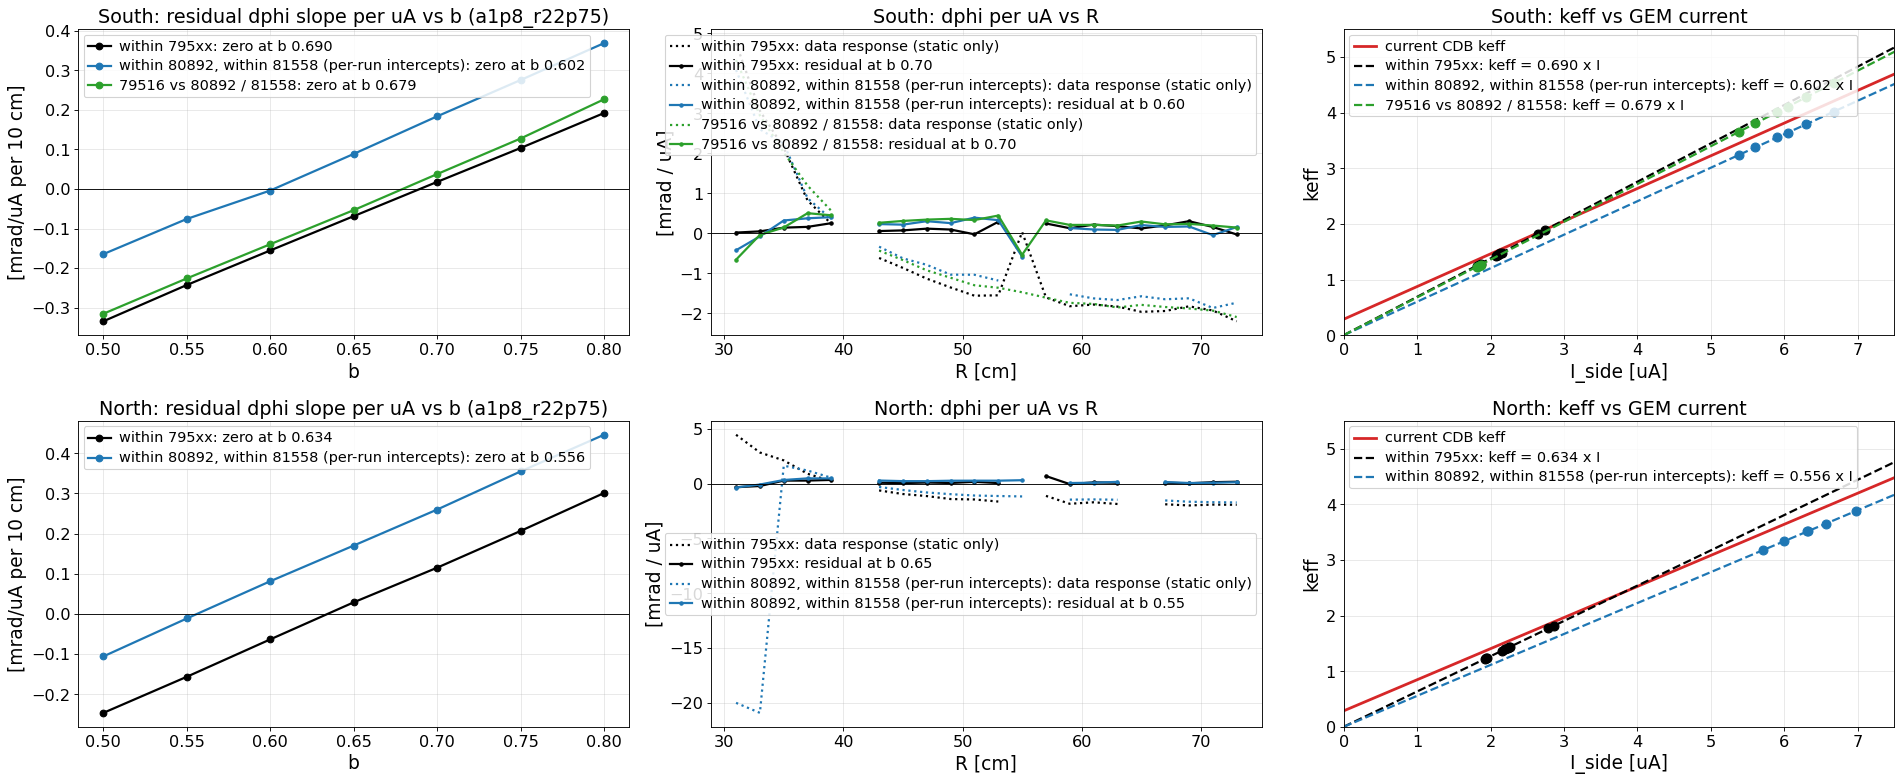

In [8]:
show(v.fig_keff_qa())

In [9]:
for m in ('a1p8_r22p75_w2_o0', 'a1p6_r25p00_w2_o0'):
    for s, nm, b0, i1, i2, sg in v.keff_table(m):
        print(f"{m.replace('_w2_o0',''):12s} {c.SIDES[s]:5s} {nm:48s}: b = {b0:.3f}  (I {i1:.2f} .. {i2:.2f} uA, sigma_I {sg:.2f})")

a1p8_r22p75  South within 795xx                                    : b = 0.690  (I 1.81 .. 2.74 uA, sigma_I 0.29)
a1p8_r22p75  South within 80892, within 81558 (per-run intercepts) : b = 0.602  (I 5.38 .. 6.68 uA, sigma_I 0.43)
a1p8_r22p75  South 79516 vs 80892 / 81558                          : b = 0.679  (I 1.81 .. 6.68 uA, sigma_I 1.99)
a1p8_r22p75  North within 795xx                                    : b = 0.634  (I 1.93 .. 2.87 uA, sigma_I 0.30)
a1p8_r22p75  North within 80892, within 81558 (per-run intercepts) : b = 0.556  (I 5.71 .. 6.98 uA, sigma_I 0.40)


a1p6_r25p00  South within 795xx                                    : b = 0.608  (I 1.81 .. 2.74 uA, sigma_I 0.29)
a1p6_r25p00  South within 80892, within 81558 (per-run intercepts) : b = 0.524  (I 5.38 .. 6.68 uA, sigma_I 0.43)
a1p6_r25p00  South 79516 vs 80892 / 81558                          : b = 0.598  (I 1.81 .. 6.68 uA, sigma_I 1.99)
a1p6_r25p00  North within 795xx                                    : b = 0.560  (I 1.93 .. 2.87 uA, sigma_I 0.30)
a1p6_r25p00  North within 80892, within 81558 (per-run intercepts) : b = 0.500  (I 5.71 .. 6.98 uA, sigma_I 0.40)


- keff through zero (no offset, unlike the CDB keff = 1.55 (0.815 I/I_79513 + 0.185)).
- α 1.8 r0 22.75: South b 0.69 (795xx), 0.60 (inside 80892 / 81558), 0.68 (79516 vs 8xxxx); North 0.63 (795xx), 0.56
  (inside 80892 / 81558): **b is ≈ 12 % lower at high luminosity on both sides** – keff grows slightly less than linearly
  with the GEM current; the CDB line lies between (its offset partly mimics this).
- QA flag: North high-luminosity data response at R < 34 cm (−20 mrad/µA) – inner-edge matching at high current.

### 2b. Which radial profile (map × b, dφ metric)

In [10]:
for s in (0, 1):
    J = v.joint_dphi(s)
    R = sorted((r['score'].min(), m, r['b'][np.argmin(r['score'])], r['b0']) for m, r in J.items())
    print(c.SIDES[s], ':')
    for sc, m, b, b0 in R:
        print(f"   {m:20s} dphi residual rms {sc:.3f} mrad/uA (min at b {b:.2f}); residual slope = 0 at b {b0:.3f}")

South :
   a1p6_r25p00_w2_o0    dphi residual rms 0.226 mrad/uA (min at b 0.60); residual slope = 0 at b 0.601
   a1p6_r22p75_w2_o0    dphi residual rms 0.232 mrad/uA (min at b 0.65); residual slope = 0 at b 0.647
   a1p7m_r25p00_w2_o0   dphi residual rms 0.235 mrad/uA (min at b 0.60); residual slope = 0 at b 0.614
   a1p6_r27p50_w2_o0    dphi residual rms 0.240 mrad/uA (min at b 0.50); residual slope = 0 at b 0.527
   a1p7m_r22p75_w2_o0   dphi residual rms 0.242 mrad/uA (min at b 0.65); residual slope = 0 at b 0.665
   a1p8_r25p00_w2_o0    dphi residual rms 0.251 mrad/uA (min at b 0.60); residual slope = 0 at b 0.628
   a1p8_r27p50_w2_o0    dphi residual rms 0.253 mrad/uA (min at b 0.50); residual slope = 0 at b 0.541
   a1p8_r22p75_w2_o0    dphi residual rms 0.259 mrad/uA (min at b 0.65); residual slope = 0 at b 0.683
   a2p0_r27p50_w2_o0    dphi residual rms 0.287 mrad/uA (min at b 0.55); residual slope = 0 at b 0.558
   a2p0_r25p00_w2_o0    dphi residual rms 0.298 mrad/uA (min at b

North :
   a1p8_r27p50_w2_o0    dphi residual rms 0.173 mrad/uA (min at b 0.50); residual slope = 0 at b 0.502
   a1p6_r27p50_w2_o0    dphi residual rms 0.174 mrad/uA (min at b 0.50); residual slope = 0 at b 0.500
   a1p6_r22p75_w2_o0    dphi residual rms 0.175 mrad/uA (min at b 0.60); residual slope = 0 at b 0.603
   a1p6_r25p00_w2_o0    dphi residual rms 0.178 mrad/uA (min at b 0.55); residual slope = 0 at b 0.560
   a1p7m_r22p75_w2_o0   dphi residual rms 0.180 mrad/uA (min at b 0.60); residual slope = 0 at b 0.618
   a1p7m_r25p00_w2_o0   dphi residual rms 0.183 mrad/uA (min at b 0.55); residual slope = 0 at b 0.572
   a1p8_r25p00_w2_o0    dphi residual rms 0.191 mrad/uA (min at b 0.60); residual slope = 0 at b 0.585
   a1p8_r22p75_w2_o0    dphi residual rms 0.195 mrad/uA (min at b 0.60); residual slope = 0 at b 0.634
   a2p0_r27p50_w2_o0    dphi residual rms 0.196 mrad/uA (min at b 0.50); residual slope = 0 at b 0.518
   a2p0_r25p00_w2_o0    dphi residual rms 0.210 mrad/uA (min at b

- **South**: α 1.6 (r0 25 / 22.75) and α 1.7 are best (0.23 mrad/µA), α 1.8 / 2.0 slightly worse; b ≈ 0.60–0.65.
- **North** (795xx only): all maps within 0.01 mrad/µA – not constrained by 795xx alone.

### 2c. Kink or b: what changes with the luminosity?
**Expectation.** At higher I_GEM there are more ions and a stronger radial field. Electrons drifting from large z are
pulled further inward, so the charge that reaches low R changes and the **inner kink of the profile moves to larger R**
with the current. A fixed-kink map would see this as an apparent b that falls with I – which is what 2a' measures
(−12 % at high luminosity).

**Test.** Two hypotheses on the per-µA dφ residuals of the clean sets (2a'), α 1.8, kinks 22.75 / 25 / 27.5 cm,
b 0.50 … 0.80:
- **H_b**: one map for all sets, b free per set;
- **H_kink**: one b for all sets, the kink free per set.

Score = √(mean over sets of rms²) [mrad/µA]; the lower one wins.

In [11]:
for s in (0, 1):
    o = v.kink_vs_b(s, '1p8')
    sc, k, per = o['H_b']
    print(f"{c.SIDES[s]}: H_b    score {sc:.3f} mrad/uA: common kink {k}, b per set: " + ', '.join(f"{n.split(' (')[0]} {b:.2f}" for n, b, r in per))
    sc, b0, per = o['H_kink']
    print(f"{' ' * len(c.SIDES[s])}  H_kink score {sc:.3f} mrad/uA: common b {b0:.2f}, kink per set: " + ', '.join(f"{n.split(' (')[0]} {k}" for n, k, r in per))

South: H_b    score 0.186 mrad/uA: common kink r22p75, b per set: within 795xx 0.70, within 80892, within 81558 0.55, 79516 vs 80892 / 81558 0.65
       H_kink score 0.185 mrad/uA: common b 0.55, kink per set: within 795xx r27p50, within 80892, within 81558 r22p75, 79516 vs 80892 / 81558 r27p50


North: H_b    score 0.176 mrad/uA: common kink r25p00, b per set: within 795xx 0.60, within 80892, within 81558 0.50
       H_kink score 0.167 mrad/uA: common b 0.50, kink per set: within 795xx r27p50, within 80892, within 81558 r25p00


**Degenerate.** Both describe the data equally well (South 0.186 vs 0.185, North 0.176 vs 0.167 mrad/µA). On a 2.5 cm
kink grid, "b 12 % lower" and "the kink moved by a few cm" look the same at R ≥ 30 cm, where the CM measures. The kink
H_kink picks per set does not even move monotonically with the current (795xx → 27.5, high luminosity → 22.75 / 25):
the grid is too coarse to follow it. The v7 scan adds the kinks 23.9 and 26.25 cm (exact 50/50 mixtures of the
solved maps; the field is linear in the charge) and b down to 0.40.

**R1 balance** – the direct handle on the kink, since the kink only shapes the inner ring: the residual per µA in R1
(30–40.5 cm) minus that in R2 + R3, at the b where the residual slope per µA vanishes. > 0: the map corrects R1 too
little for the change in current; < 0: too much.

South kink r22p75  within 795xx                                    : b 0.690, R1 - R2/R3 +0.039 mrad/uA
South kink r22p75  within 80892, within 81558 (per-run intercepts) : b 0.602, R1 - R2/R3 -0.033 mrad/uA
South kink r22p75  79516 vs 80892 / 81558                          : b 0.679, R1 - R2/R3 -0.021 mrad/uA
South kink r25p00  within 795xx                                    : b 0.635, R1 - R2/R3 +0.045 mrad/uA
South kink r25p00  within 80892, within 81558 (per-run intercepts) : b 0.548, R1 - R2/R3 -0.026 mrad/uA
South kink r25p00  79516 vs 80892 / 81558                          : b 0.625, R1 - R2/R3 -0.013 mrad/uA
South kink r27p50  within 795xx                                    : b 0.548, R1 - R2/R3 +0.062 mrad/uA
South kink r27p50  within 80892, within 81558 (per-run intercepts) : b 0.500, R1 - R2/R3 -0.164 mrad/uA
South kink r27p50  79516 vs 80892 / 81558                          : b 0.538, R1 - R2/R3 +0.001 mrad/uA
North kink r22p75  within 795xx                                 

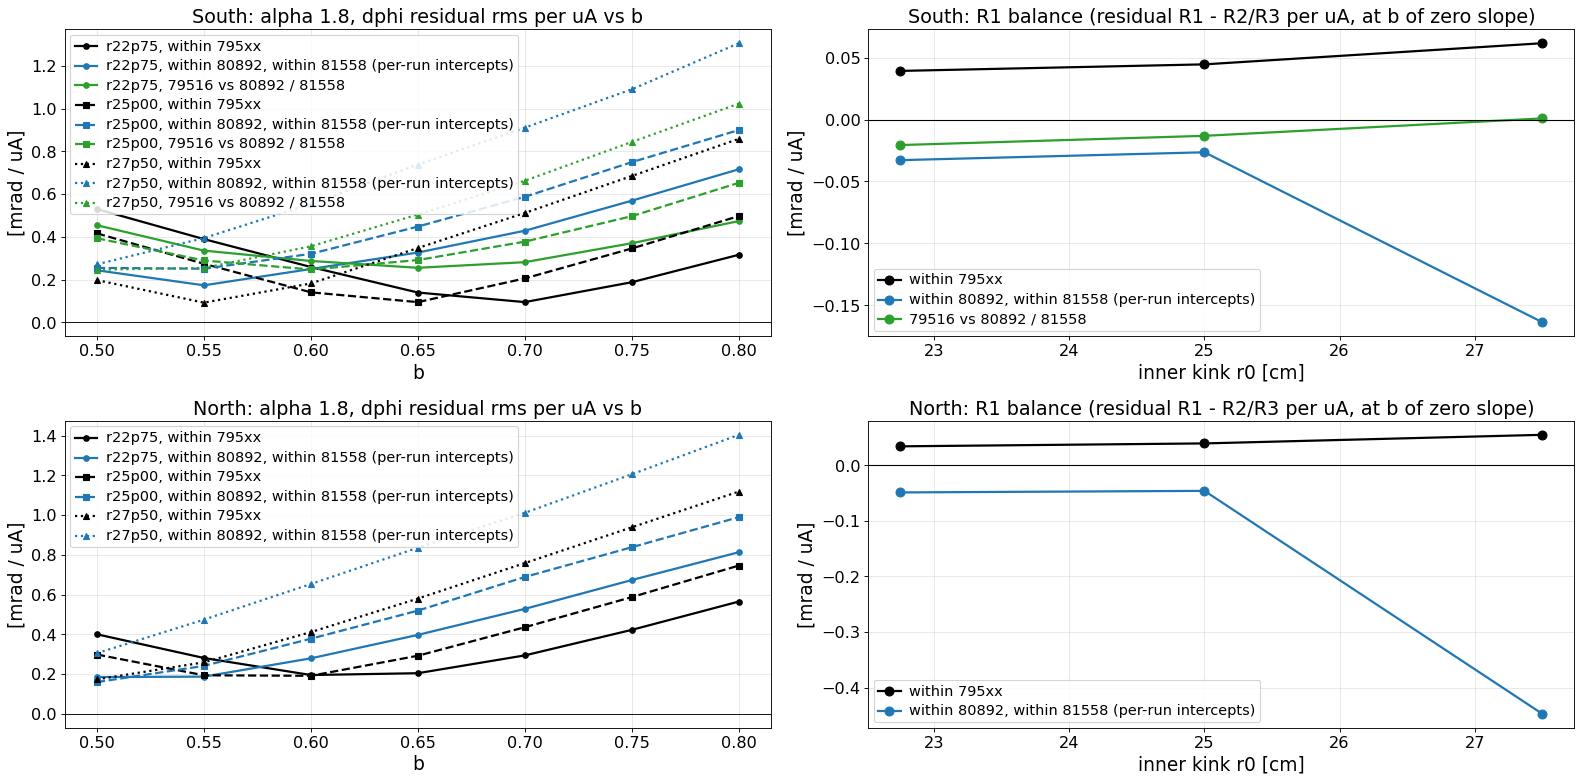

In [12]:
for s in (0, 1):
    for k, nm, b0, d in v.r1_balance(s, '1p8'):
        print(f"{c.SIDES[s]:5s} kink {k}  {nm:48s}: b {b0:.3f}, R1 - R2/R3 {d:+.3f} mrad/uA")
show(v.fig_kink_vs_b('1p8'))

- **795xx (low current)**: R1 is under-corrected for every kink (+0.04 … +0.06 mrad/µA, growing with the kink), so it
  prefers a kink **at or below 22.75 cm**. The lever is weak: σ_I is only 0.3 µA.
- **High luminosity, inside 80892 / 81558**: R1 is over-corrected (−0.03 … −0.05) for 22.75 and 25, and strongly for
  27.5 (−0.16 S, −0.45 N). The cross-period set 79516 vs 8xxxx (South) crosses zero between 25 and 27.5 cm.
- So, relative to a fixed map with b fitted per set, the inner ring wants **more** correction per µA at low luminosity
  and **less** at high luminosity. That is the signature of a profile shape that changes with the current, not only its
  scale. The size is a few cm of kink, below what the v5 grid resolves → v7.
- For a K0s run at one luminosity the two descriptions give the same correction at R ≥ 30 cm: the per-set b absorbs it.
  It matters for one map across luminosities, and for the region below 30 cm that the CM does not see (tracks do, via
  the INTT/MVTX pointing).

## 3. Static (v5 grid at 795xx: IFC, OFC, frame charge)
**Quantities.** dφ vs R vs the aligned truth (K0s-weighted φ average). Decomposition dφ(R) = ω + 100·a/R + rest:
ω = rotation (free), a = constant RΔφ = **sideways shift of all tracks** (DCA, vertexing; invisible to the K0s mass and
balance), rest = curvature and wiggles. **Step at a module boundary** (40.5 cm R1/R2, 57.5 cm R2/R3): the jump across the
boundary from straight lines fitted to 3 points on each side – a kink a track cannot follow, made by the module frames.

### 3a. Does the CM measure the CDB right? The sideways shift, CM vs tracks

In [13]:
for side, lab, w, a, r in v.shift_table():
    print(f"{side:5s} {lab:28s}: rotation {w:+.2f} mrad, sideways shift a {a:+.2f} mm, rest {r:.2f} mrad")
print('single TPC-only tracks 79513 (CDB): constant sideways miss South -0.68 mm, North -1.37 mm (opposite sign convention)')

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/v5ana.py:330: RuntimeWarning: Mean of empty slice
  _DP[k] = np.nanmean(P, axis=0) if P else np.full(len(ta.PRC), np.nan)


South 795xx, CDB                  : rotation +2.43 mrad, sideways shift a +0.50 mm, rest 0.51 mrad
South 795xx, ours (grid point)    : rotation +0.59 mrad, sideways shift a +0.63 mm, rest 0.46 mrad
South 80892/81558, CDB            : rotation +3.86 mrad, sideways shift a +0.13 mm, rest 1.20 mrad
South no beam 75073, CDB static   : rotation +0.81 mrad, sideways shift a +1.31 mm, rest 0.61 mrad
South no beam 83319, CDB static   : rotation +1.46 mrad, sideways shift a +0.82 mm, rest 0.49 mrad
North 795xx, CDB                  : rotation +0.48 mrad, sideways shift a +1.45 mm, rest 0.24 mrad
North 795xx, ours (grid point)    : rotation -2.17 mrad, sideways shift a +2.62 mm, rest 0.22 mrad
North 80892/81558, CDB            : rotation +1.52 mrad, sideways shift a +1.47 mm, rest 1.17 mrad
North no beam 75073, CDB static   : rotation -1.36 mrad, sideways shift a +2.18 mm, rest 0.53 mrad
North no beam 83319, CDB static   : rotation -0.39 mrad, sideways shift a +3.05 mm, rest 0.53 mrad
single TPC

- The CDB has a **uniform sideways shift**: South 0.50 mm, North 1.45 mm on the CM; the tracks see 0.68 / 1.37 mm
  independently. Apart from rotation and shift the CDB is flat (0.24 / 0.51 mrad left): consistent with the K0s (balanced,
  η-symmetric) – a shift moves both daughters and the vertex together.
- The shift is static (no beam: South 0.8–1.3 mm, North 2.2–3.1 mm) and changes with time in North.
- Our v5 grid point has 2.6 mm in North (worse than the CDB).

### 3b. Static grid and the dφ-flat solution

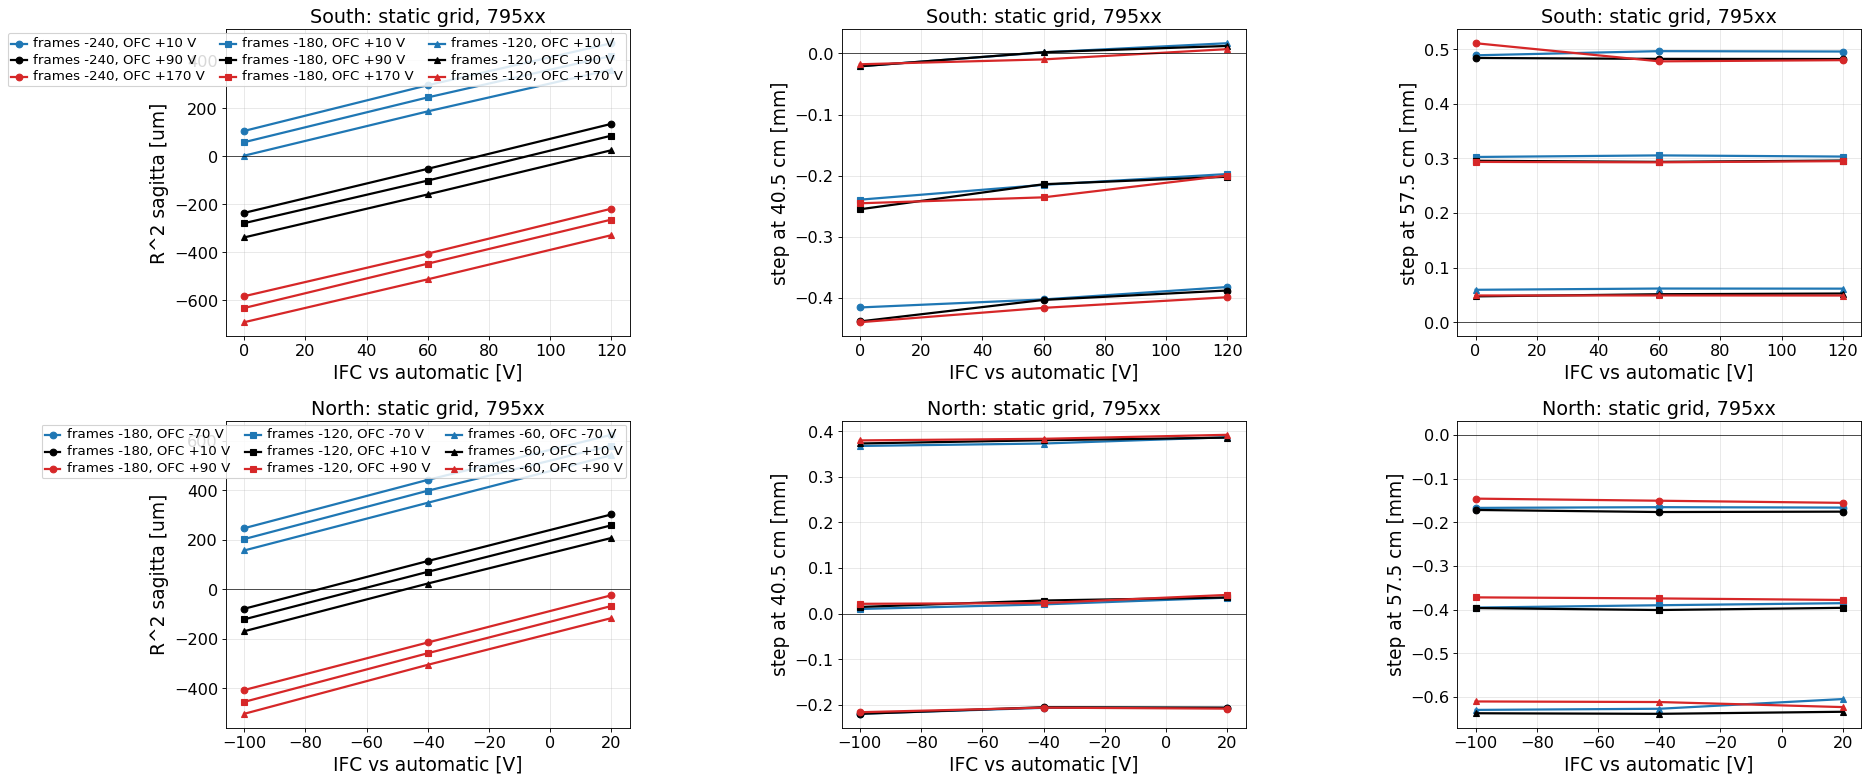

In [14]:
show(v.fig_static_grid())

South lambda 0.0: IFC   -36 V, OFC   -40 V, frames  -113 -> dphi rms about mean 0.47 mrad, slope -0.02/10cm
South lambda 0.1: IFC   -38 V, OFC   -34 V, frames  -133 -> dphi rms about mean 0.47 mrad, slope -0.02/10cm
South lambda 1.0: IFC   -39 V, OFC   -16 V, frames  -166 -> dphi rms about mean 0.48 mrad, slope -0.05/10cm


North lambda 0.0: IFC  -138 V, OFC   -49 V, frames  -161 -> dphi rms about mean 0.25 mrad, slope -0.01/10cm
North lambda 0.1: IFC  -137 V, OFC   -42 V, frames  -163 -> dphi rms about mean 0.25 mrad, slope -0.02/10cm
North lambda 1.0: IFC  -129 V, OFC   -16 V, frames  -170 -> dphi rms about mean 0.26 mrad, slope -0.08/10cm


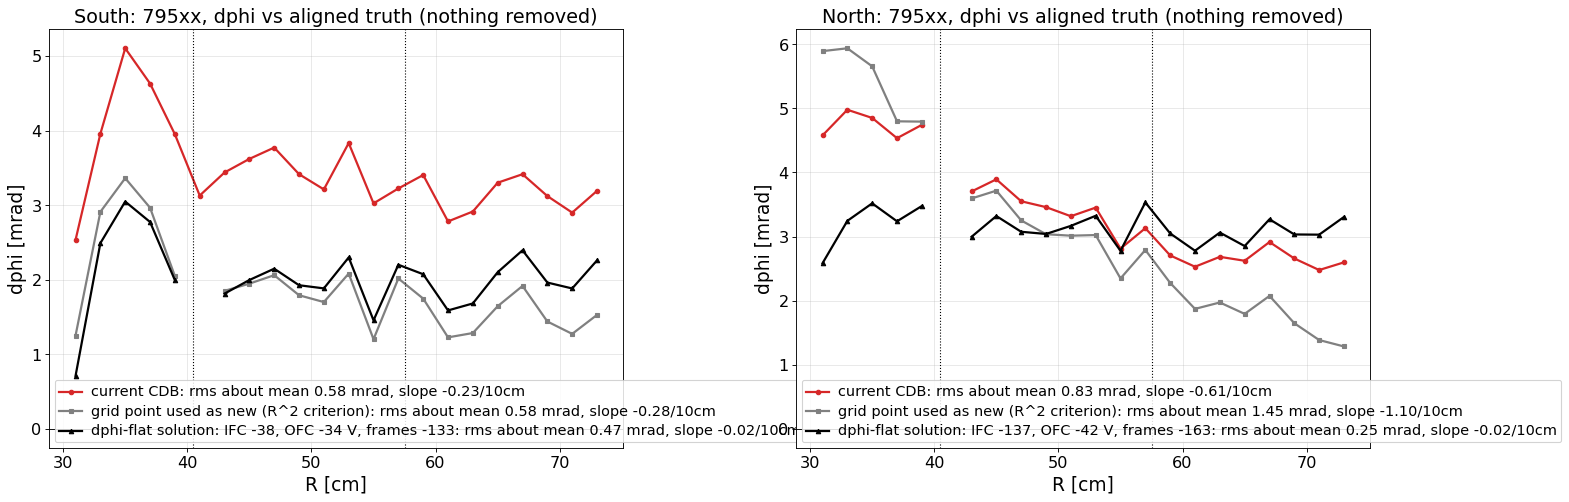

In [15]:
for s in (0, 1):
    for lam in (0.0, 0.1, 1.0):
        o = v.static_fit_dphi(s, lam); f, sl = v.flatness(o['pred'])
        print(f"{c.SIDES[s]:5s} lambda {lam:3.1f}: IFC {o['IFC']:+5.0f} V, OFC {o['OFC']:+5.0f} V, frames {o['frames']:+5.0f} -> dphi rms about mean {f:.2f} mrad, slope {sl:+.2f}/10cm")
show(v.fig_static_dphi_fit())

- **South**: IFC ≈ −38 V, OFC ≈ −34 V, frames ≈ −133: dφ rms about the mean 0.47 mrad (CDB 0.58).
- **North**: needs IFC ≈ −130 … −140 V (at the edge of the grid), OFC ≈ −40 V, frames ≈ −165: 0.25 mrad (CDB 0.83) – the
  IFC removes the 2.6 mm sideways shift. A large effective voltage: the North shift is static and time dependent,
  likely not the field cage itself → to be understood (per period, alignment of the North CM vs pads).
- The R² target of v2 is satisfied automatically by a flat dφ – only approximately; see 3c.

### 3c. Joint static fit: dφ flat, R² = 0, pointing = 0, flat module steps
Flat dφ alone (3b) leaves South with R² = +100 µm and pointing 0.5 mm, because a flat-in-R dφ about its mean does not
fix the curvature a track keeps. The joint fit minimises, per side,

  Σ_R [(dφ − ⟨dφ⟩)/0.1 mrad]² / n_R + (R²/50 µm)² + (pointing/0.3 mm)² + (step₄₀.₅/0.1 mm)² + (step₅₇.₅/0.1 mm)²
  + λ |knobs − prior|²  (prior 0 V vs automatic, frames −180; λ = 0.1),

with each quantity linear in (IFC/100 V, OFC/100 V, frames/60), fitted over the 27 points of the v5 grid (795xx, α 1.8 at
the ΔI b). The rotation ⟨dφ⟩ stays free. The scales set what "good" means: 0.1 mrad of dφ, 50 µm of sagitta (≈ 1 % of
N⁻/N⁺ at 2 GeV), 0.3 mm of pointing (the INTT can take that), 0.1 mm per step. The fit is repeated with other weights.

                              IFC    OFC  frames | dphi rms  shift    R^2  point  step1  step2
                              [V]    [V]         |   [mrad]   [mm]   [um]   [mm]   [mm]   [mm]
South current CDB                -      -       - |     0.58  +0.50    -31  +0.41  -0.17  +0.28
South dphi only               -37    -38    -119 |     0.47  +0.03   +101  +0.51  -0.03  +0.07
South joint (default)         -36    -17    -107 |     0.47  +0.01     +0  +0.05  +0.01  +0.02
South joint, pointing x4      -37    -16    -107 |     0.47  +0.00     -4  +0.02  +0.01  +0.02
South joint, steps x4         -36    -17    -106 |     0.47  +0.01     +0  +0.05  +0.02  +0.02
South joint, no prior         -36    -17    -106 |     0.47  +0.01     +0  +0.05  +0.01  +0.02
North current CDB                -      -       - |     0.83  +1.45    +50  +1.71  -0.31  -0.13
North dphi only              -138    -47    -162 |     0.25  +0.02    +21  +0.13  -0.16  -0.24
North joint (default)        -138    -41    -165

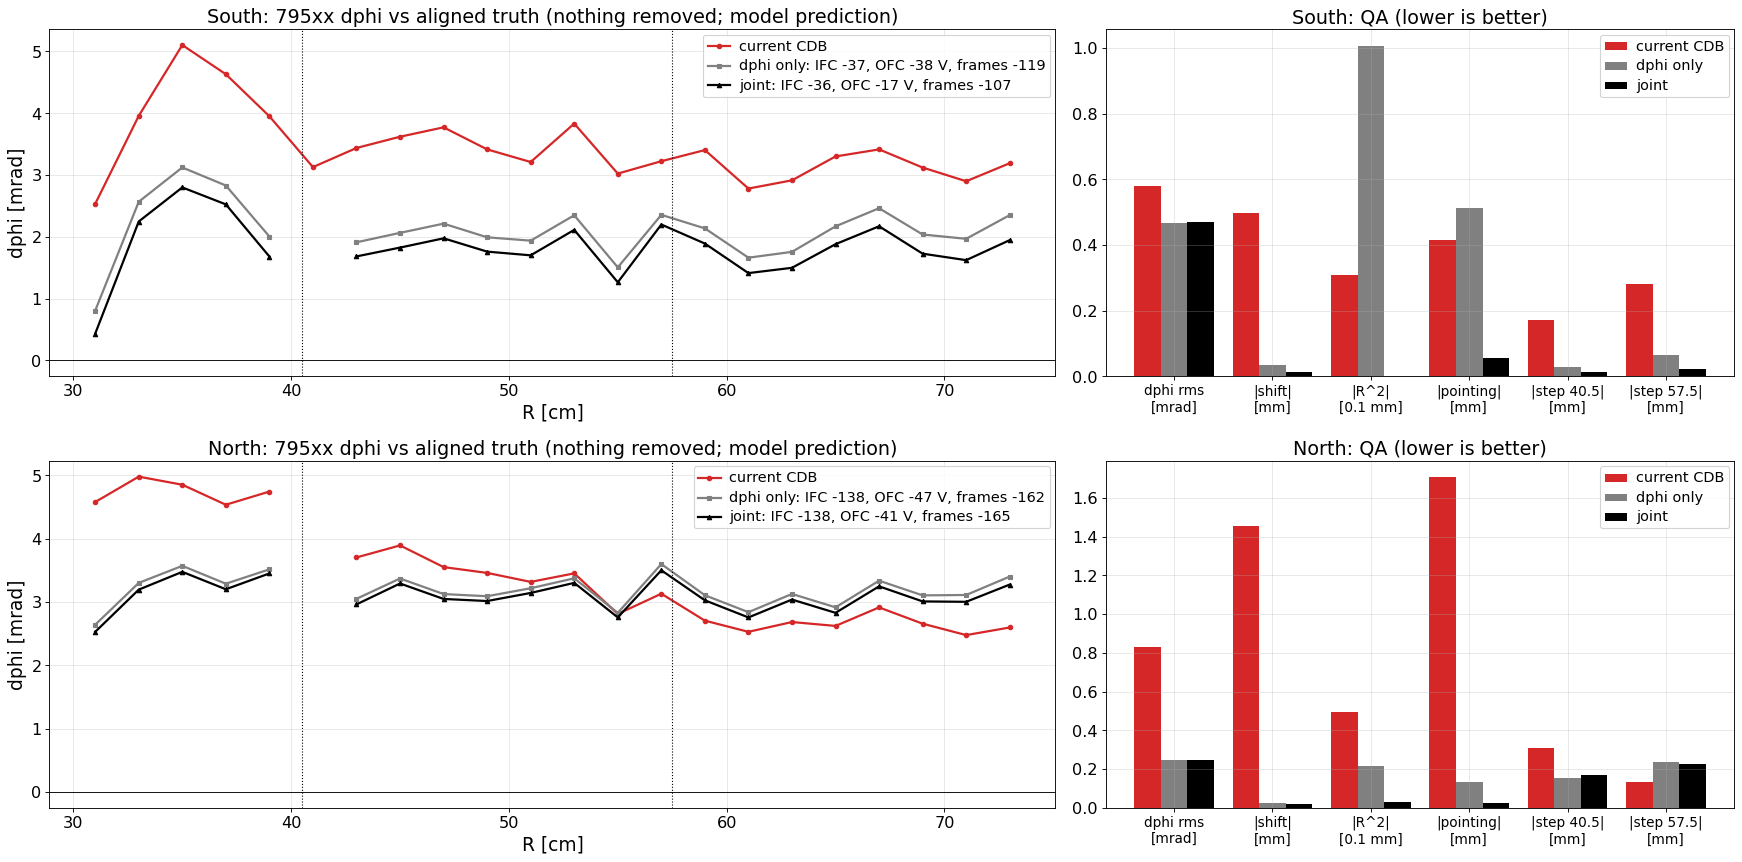

In [16]:
print(f"{'':5s} {'':20s} {'IFC':>6s} {'OFC':>6s} {'frames':>7s} | {'dphi rms':>8s} {'shift':>6s} {'R^2':>6s} {'point':>6s} {'step1':>6s} {'step2':>6s}")
print(f"{'':5s} {'':20s} {'[V]':>6s} {'[V]':>6s} {'':>7s} | {'[mrad]':>8s} {'[mm]':>6s} {'[um]':>6s} {'[mm]':>6s} {'[mm]':>6s} {'[mm]':>6s}")
for side, lab, i, o, f, fl, a, r2, pt, s1, s2 in v.joint_table():
    k = '      -      -       -' if np.isnan(i) else f"{i:+6.0f} {o:+6.0f} {f:+7.0f}"
    print(f"{side:5s} {lab:20s} {k} | {fl:8.2f} {a:+6.2f} {r2:+6.0f} {pt:+6.2f} {s1:+6.2f} {s2:+6.2f}")
show(v.fig_static_joint())

Left: dφ vs R (model prediction from the grid, 795xx, nothing removed); right: the QA numbers in absolute value (R² in
units of 0.1 mm). IFC / OFC are relative to the automatic voltages.

**South: IFC −36 V, OFC −17 V, frames −107.**
- dφ rms 0.47 mrad (CDB 0.58), sideways shift 0.01 mm (CDB 0.50), R² 0 µm (CDB −31), pointing 0.05 mm (CDB 0.41), steps
  +0.01 / +0.02 mm (CDB −0.17 / +0.28): **better than the CDB in every number**.
- Versus dφ-only, only the OFC moves (−38 → −17 V). That is the knob that takes out R² (+100 µm) and pointing (0.5 mm)
  without making dφ any worse: the dφ-flat solution is degenerate in that direction.

**North: IFC −138 V, OFC −41 V, frames −165.**
- dφ rms 0.25 mrad (CDB 0.83), shift 0.02 mm (CDB 1.45), R² −3 µm (CDB +50), pointing 0.03 mm (CDB 1.71).
- The **module steps stay** at −0.17 / −0.22 mm whatever the weights (steps ×4 changes nothing). No combination of field
  cage and frame charge flattens both North boundaries: it is in the frame *shape* or in the geometry (3d).
- The large IFC is an **effective** knob: it is what removes the static, time-dependent North sideways shift (3a). A
  real −138 V on the North inner field cage is unlikely; a geometric cause (CM or pad plane in North, or the
  inner-field-cage position) would produce the same 1/R shape.

**Left over in South: the R1 bump.** Both the CDB and the joint solution keep ≈ +1 mrad at R 31–39 cm (peak at 35 cm)
relative to R2/R3, and no combination of IFC, OFC and frame charge removes it: the knobs move R1 together with the rest.
It is the inner shape of the space charge, the same region the R1 balance (2c) tests, so v7 (finer kinks) is the place
to fix it. North has no such bump (its R1 sits at the R2/R3 level).

**Robustness.** Weights ×4 on pointing or on the steps, or no prior, move the knobs by ≤ 2 V and ≤ 2 in frame charge:
the solution is set by the data, not by the weights. The v7 scan uses it as the base static (South frames rounded to
−110) and checks it with ±40 around it.

**What it means for tracks.**
- R² → 0 on both sides: the K0s balance should be ≈ 0 (K0s = +4 + 1.11 × R², Section 1b).
- Pointing and sideways shift → 0: the TPC-only tracks should no longer miss the vertex by the constant 0.7 / 1.4 mm the
  CDB leaves (rDCA in 79513). This is the clearest track-level prediction of the new static, and the one to check first.

### 3d. Module frames with beam: the v6 test (m = 120 frame maps)
The CDB frame maps keep only the φ harmonics m ≤ 24, so the frame field is smeared over ±7° around each sector edge
and leaves module-wide E_r plateaus (−0.07 R1 / +0.07 R3 V/cm). The m = 120 Rossegger maps (35 min per side) resolve the
frames; a radial Gaussian smoothing (0.5 / 1 cm) varies the steepness. v6: four frame maps × frame charge −120 / −180 /
−240, on the v5 static (South IFC −5 / OFC +7 V, North −32 / +41 V) with α 1.8 at the ΔI b, 795xx.

Columns: dφ rms about the mean, sideways shift, R², pointing, module steps (as in 3c), and the **sector-edge swing**
per ring: max − min of RΔφ within ±6° of the sector edge [mm]. It is set by the one or two 0.5° bins right next to
the edge (15–17°), where the CM stripes end: read it as "how large the edge spike is", not as a smooth shape. Field off
raw (grey) swings by 1–2.5 mm near the edges, so part of what is left at the edge with beam is CM / pad geometry, not
field.

                          dphi  shift   R^2  point  step1  step2 | edge swing R1 / R2 / R3 [mm]


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/v5ana.py:330: RuntimeWarning: Mean of empty slice
  _DP[k] = np.nanmean(P, axis=0) if P else np.full(len(ta.PRC), np.nan)
/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/calib.py:29: RuntimeWarning: Mean of empty slice
  _cache[k] = np.nanmean([aq.wprof(aq.full_aligned(r, ta.v4_tag(b, tag), s)) for r, b in aq.blocks(runs)], axis=0)
/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/v5ana.py:595: RuntimeWarning: Mean of empty slice
  return 0.5 * (e[1:] + e[:-1]), np.nanmean(out, axis=0)


South CDB frames, -120    0.55  +0.55    +3  +0.60  -0.02  +0.06 | 1.04 / 1.76 / 0.82
South CDB frames, -180    0.60  +0.67   +58  +0.96  -0.24  +0.30 | 1.07 / 1.84 / 0.84
South CDB frames, -240    0.66  +0.78  +103  +1.28  -0.42  +0.49 | 1.13 / 1.81 / 0.91
South m120, -120          0.52  +0.39   -24  +0.32  +0.04  +0.02 | 0.76 / 1.33 / 0.63
South m120, -180          0.54  +0.43   -18  +0.39  -0.17  +0.08 | 1.13 / 1.35 / 0.59
South m120, -240          0.57  +0.48   +65  +0.81  -0.34  +0.44 | 2.01 / 1.21 / 0.87
South m120 s0.5, -180     0.53  +0.39   -21  +0.34  -0.02  -0.19 | 1.11 / 1.37 / 0.56
South m120 s1, -180       0.57  +0.32   -50  +0.13  +0.29  -0.39 | 1.38 / 1.50 / 0.56
North CDB frames, -120    0.93  +1.64   -29  +1.51  +0.03  -0.39 | 1.48 / 2.23 / 1.10
North CDB frames, -180    0.99  +1.77   +12  +1.83  -0.20  -0.17 | 1.46 / 2.17 / 0.97
North CDB frames, -240    1.07  +1.90   +39  +2.08  -0.39  -0.02 | 1.44 / 2.11 / 0.84
North m120, -120          0.83  +1.45   -56  +1.20  +0

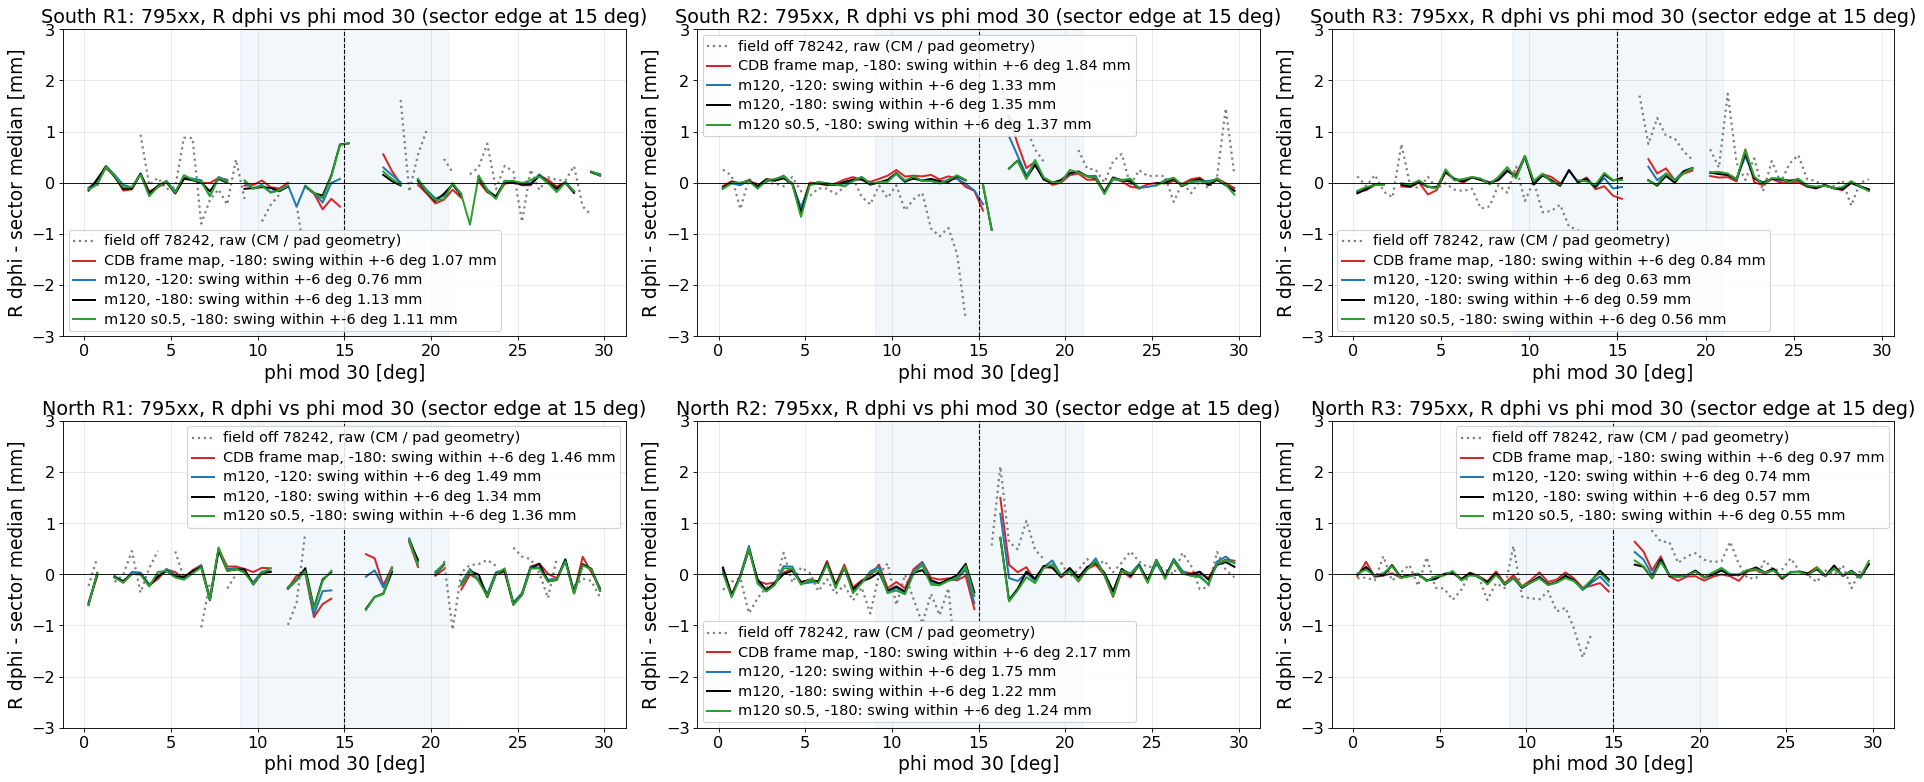

In [17]:
print(f"{'':5s} {'':18s} {'dphi':>5s} {'shift':>6s} {'R^2':>5s} {'point':>6s} {'step1':>6s} {'step2':>6s} | edge swing R1 / R2 / R3 [mm]")
for row in v.v6_table():
    side, lab, fl, a, r2, pt, s1, s2, w1, w2, w3 = row
    print(f"{side:5s} {lab:18s} {fl:5.2f} {a:+6.2f} {r2:+5.0f} {pt:+6.2f} {s1:+6.2f} {s2:+6.2f} | {w1:4.2f} / {w2:4.2f} / {w3:4.2f}")
show(v.fig_edges())

RΔφ vs φ mod 30° per ring (sector edge at 15°, ±6° shaded), median of each sector subtracted; grey: field off raw (CM /
pad geometry).

- **m = 120 is better than the CDB frame maps at the edges**: the swing within ±6° drops by 25–45 % (South R2 1.8 →
  1.35 mm, North R2 2.2 → 1.2, North R3 1.0 → 0.55 mm). The frame field is local, as it should be; the CDB truncation
  spreads it over the whole module.
- It also helps the module-averaged numbers: South sideways shift 0.67 → 0.43 mm and pointing 0.96 → 0.39 mm at −180;
  North shift 1.77 → 1.50 mm (the rest of the North shift is the static issue of 3c).
- **Steepness**: unsmoothed or 0.5 cm is best. 1 cm smoothing makes the steps worse (South −0.39, North −0.80 mm at
  57.5 cm) – the frames are steep, not smeared.
- **Frame charge**: −120 … −180 (the joint fit: −107 S / −165 N). At −240 with m = 120 the R1 edge swing doubles
  (South 2.0, North 2.75 mm): too much charge.
- **North module steps**: no frame map or charge flattens both boundaries at once. At −120 the 40.5 cm step is 0 and the
  57.5 cm step is −0.42 mm; at −240 it is the other way round (−0.42 / −0.01). Both boundaries would need a different
  frame charge – R1/R2 and R2/R3 frames are not one knob in North. This is not a frame shape we can tune away with one
  charge.
- **Open: the no-beam step at 40.5 cm** (−1 mm, absent in the beam data). The frames are in both, so a frame map alone
  does not explain it. One candidate is the space-charge map: the ion-density map is zero in the module gaps, which
  puts a step at the R1/R2 boundary in the beam correction that may be compensating a real one. To be checked by filling
  or smoothing the gaps of the density map, and in the v7 static-only beam configurations.
- The offline φ-averaged frame model does not reproduce the PHGarfield response, so frame tests have to go through
  PHGarfield (as here).

## 4. The static per run (space charge taken out)

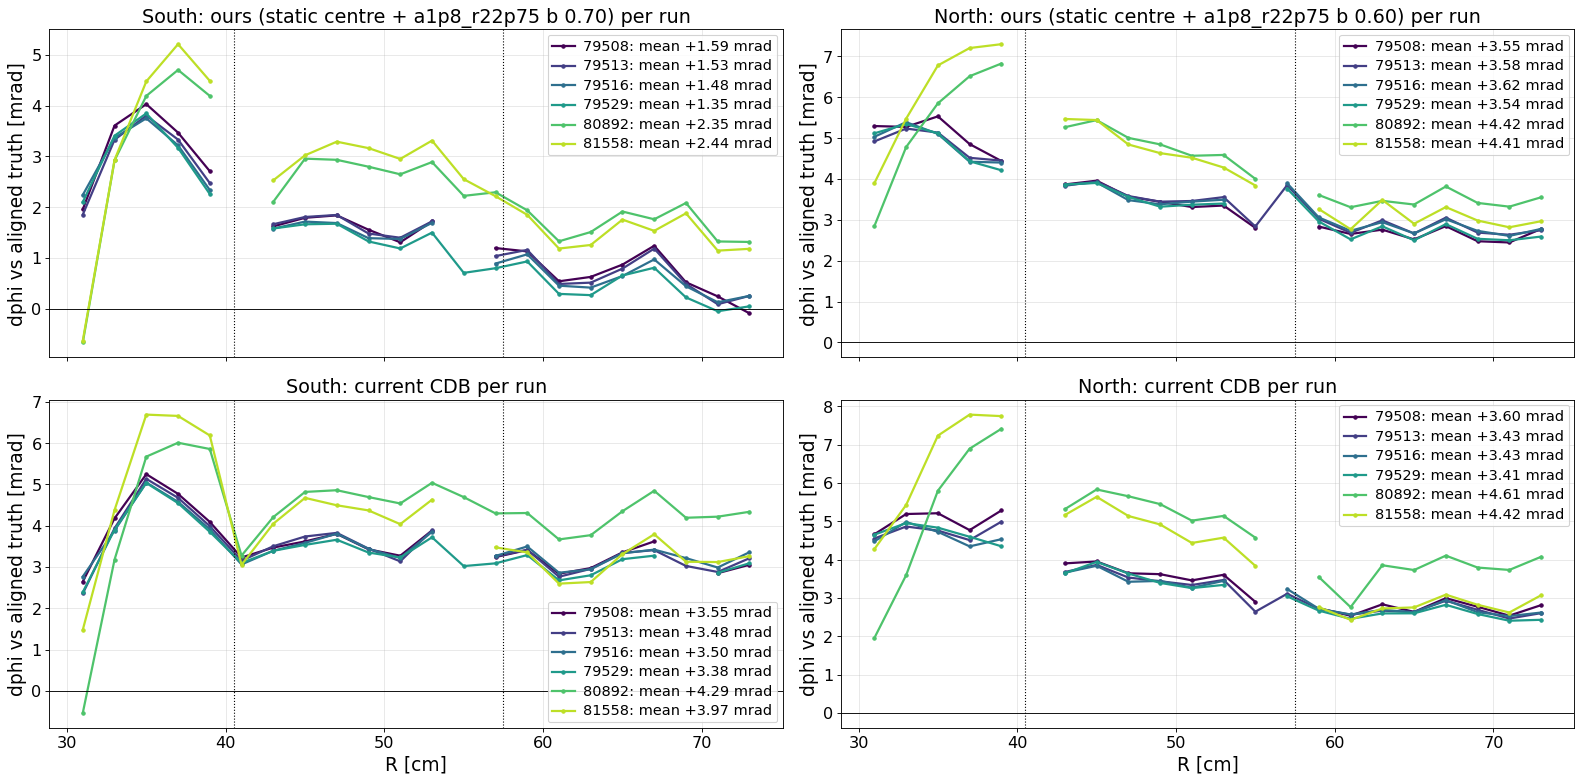

In [18]:
show(v.fig_runs_dphi())

Top: ours (static centre + α 1.8 at the ΔI b); bottom: the CDB; dφ per run, nothing removed. South is the same in every
run; North moves between 795xx and 80892 / 81558.

## 5. Final: new vs CDB against the aligned truth, nothing removed
### 5a. dφ vs R, φ-averaged and in four φ bins (795xx)

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/slidestyle.py:35: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  fig.tight_layout()


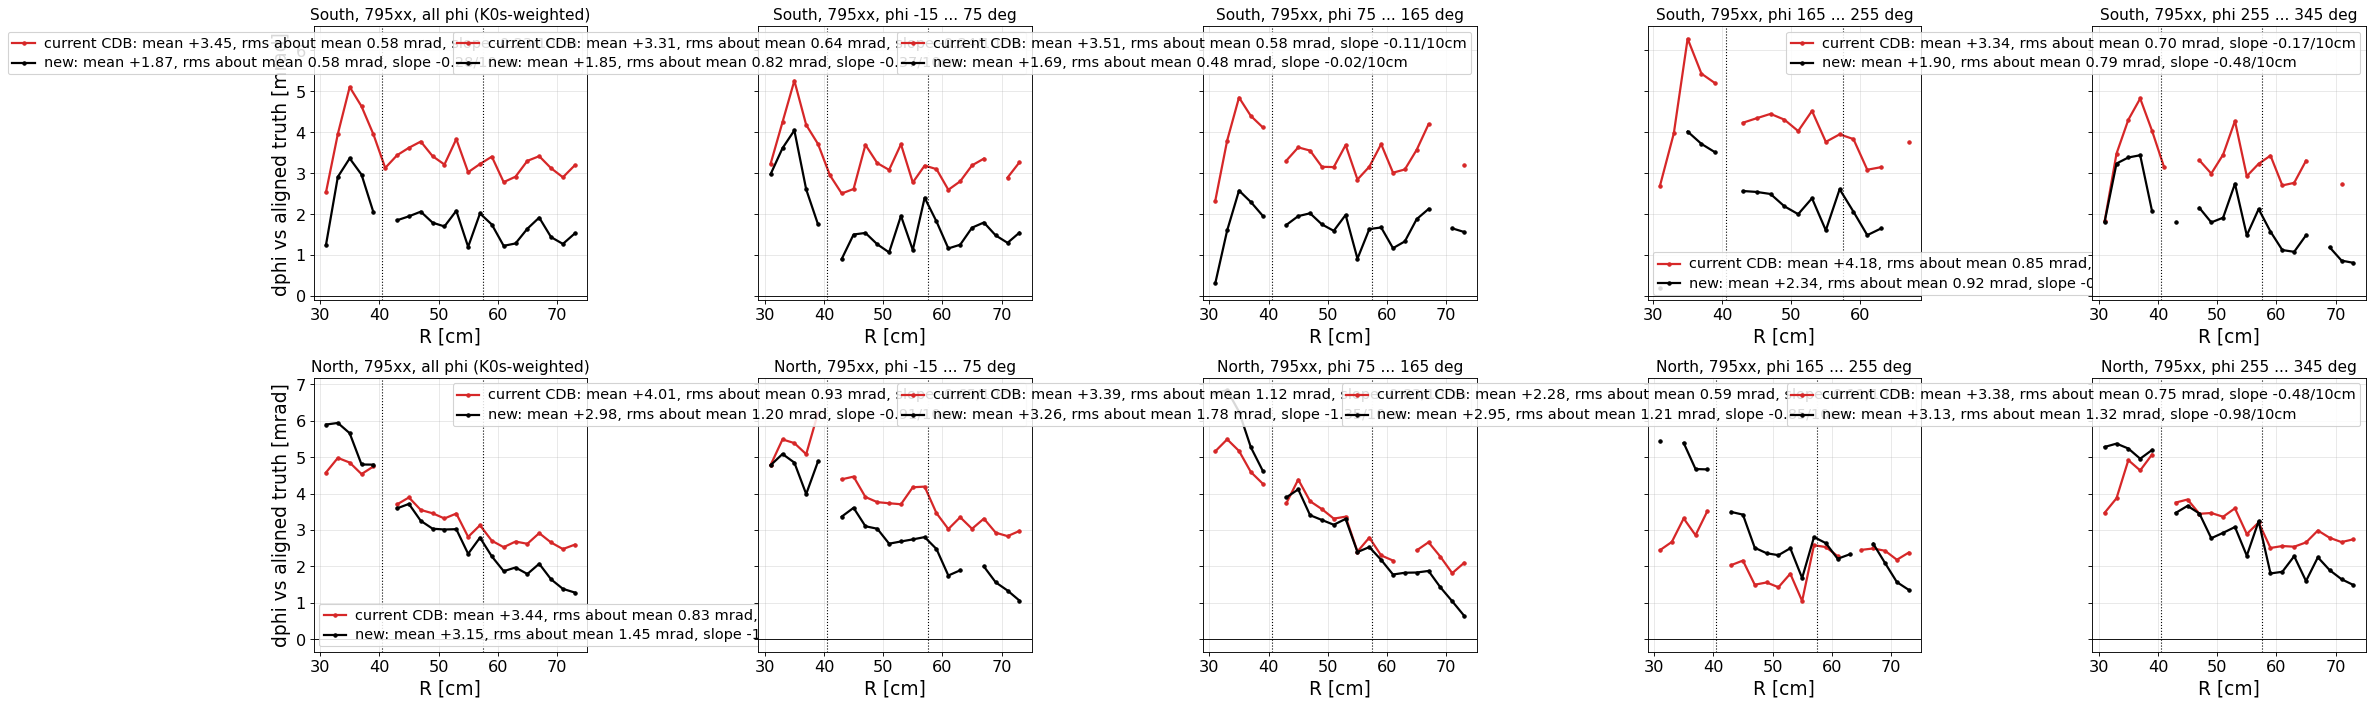

In [19]:
show(v.fig_cmp_dphi())

### 5b. dR vs R from all two-row clusters (795xx)

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/v5ana.py:356: RuntimeWarning: Mean of empty slice
  return np.nanmean(D, axis=0) if D else np.full(len(E) - 1, np.nan)


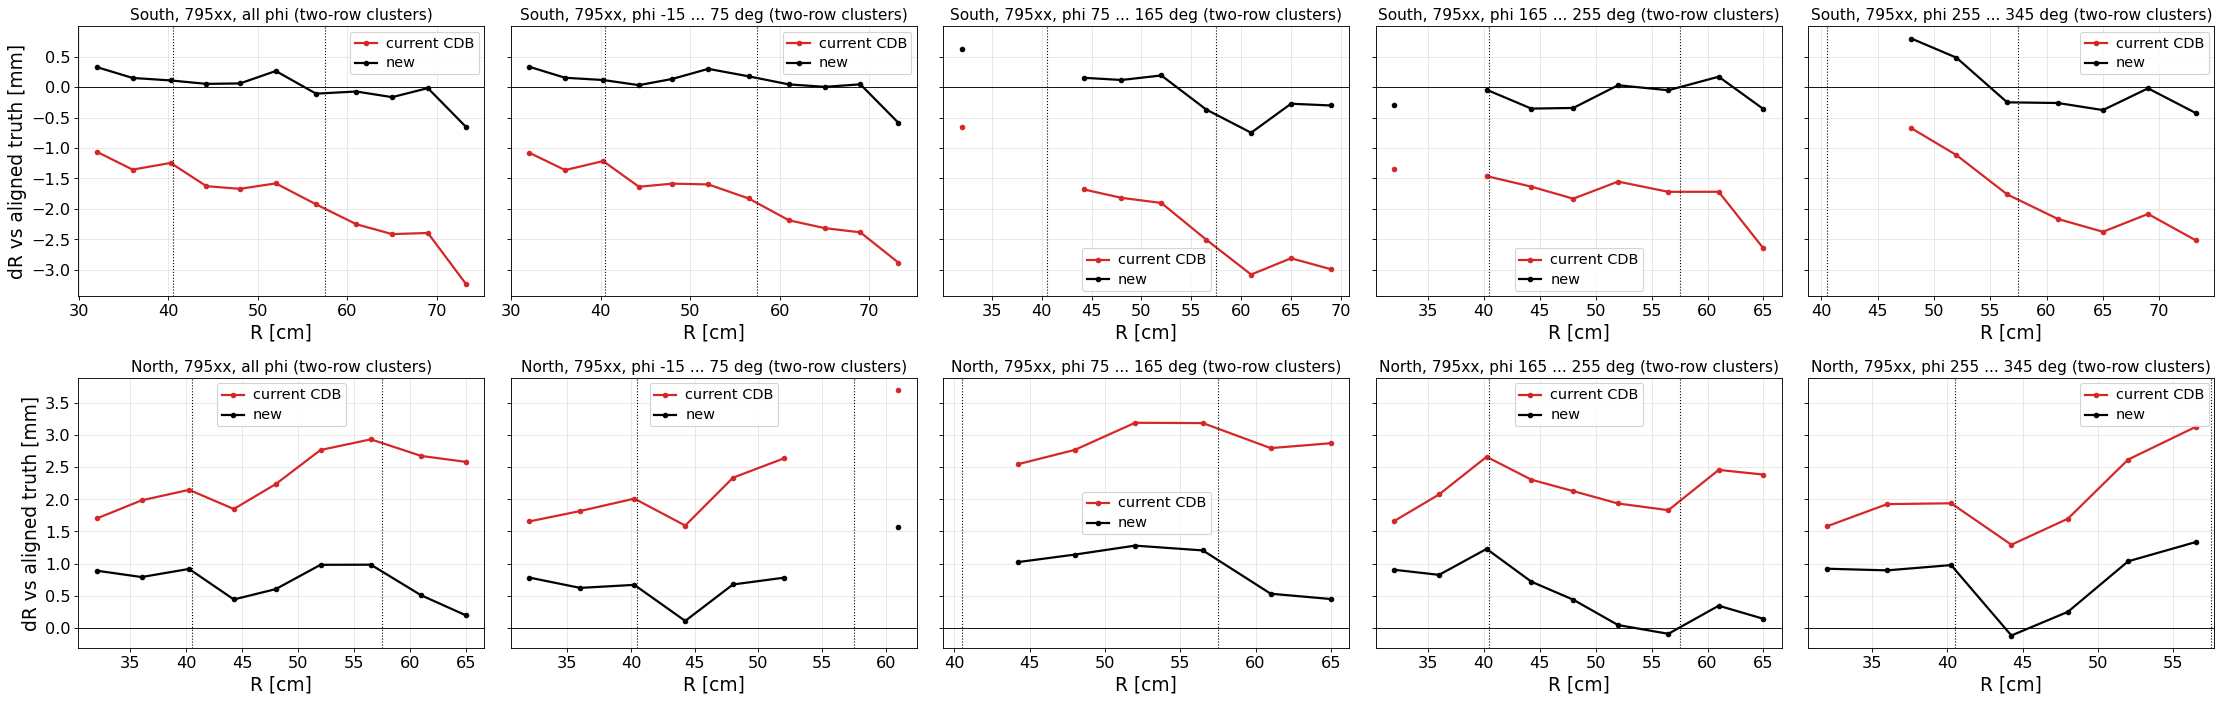

In [20]:
show(v.fig_cmp_dR())

- dφ: South the same flatness as the CDB with a smaller rotation; North the larger sideways shift (Section 3a).
- **dR: the new correction is much better** – South ≈ 0 ± 0.3 mm flat in R (CDB −1 … −3 mm), North +0.5 … +1 mm
  (CDB +2 … +3 mm). All two-row clusters are used (a centroid between two pad rows is a valid radial measurement; only
  one-row clusters saturate).

### 5c. Per 30° sector

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/v5ana.py:250: RuntimeWarning: Mean of empty slice
  D = np.nanmean(D, axis=0)


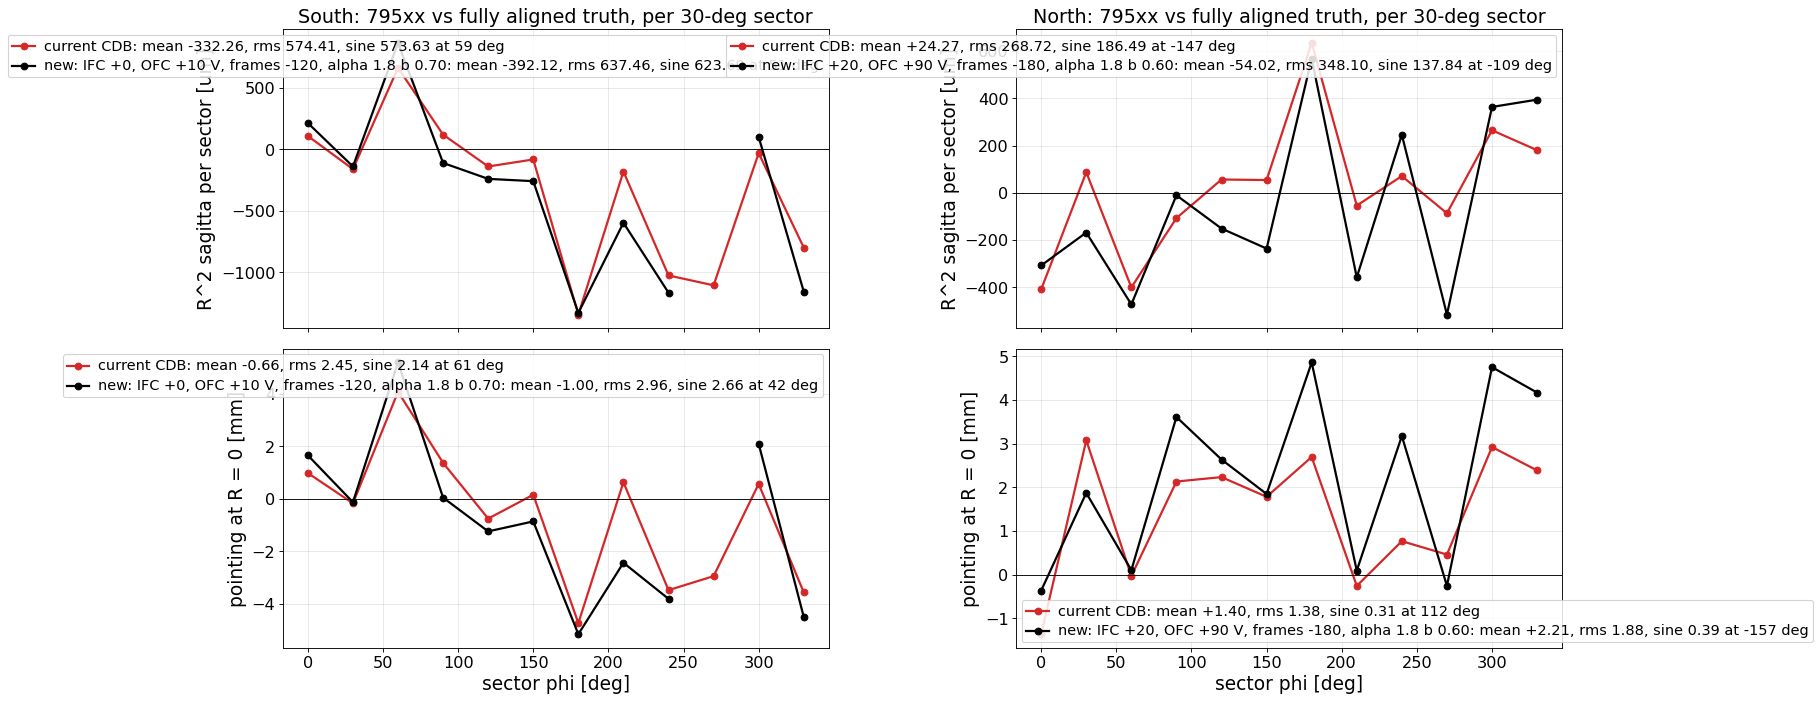

In [21]:
show(v.fig_final_sectors())

## 6. Summary and next
1. **Alignment**: rigid + 72 modules + fine R profile from raw field off; K0s balance ↔ laser R² with slope 1, no offset.
2. **The CM measures the CDB correctly**: its sideways shift (0.5 / 1.45 mm) is seen identically by the tracks.
3. **Space charge**: keff linear in the GEM current through zero. South α 1.6–1.7, b ≈ 0.60–0.70 (α 1.8 r22.75: 0.69 at
   795xx, 0.60 at high luminosity); North 0.63 / 0.56.
4. **Kink vs b (2c)**: degenerate on the v5 grid. The R1 balance shows the inner-ring response changes with the current
   by more than a scale: under-corrected at low, over-corrected at high luminosity → a kink that moves with I is
   plausible but not yet resolved.
5. **Joint static (3c)**: South IFC −36 / OFC −17 V / frames −107; North IFC −138 / OFC −41 V / frames −165.
   dφ flatter than the CDB, R² ≈ 0, pointing and sideways shift ≈ 0 on both sides; robust to the weights. North keeps
   −0.2 mm module steps, and its IFC is an effective knob for a static, time-dependent shift.
6. **Frames (3d)**: m = 120 maps beat the CDB maps (m ≤ 24) at the sector edges by 25–45 % and reduce the South
   shift / pointing; no smoothing (or ≤ 0.5 cm); charge −110 … −165.

**v7 scan (submitted, 335 jobs)**, on the joint static with m = 120 frames (South frames −110, North −165):
- **M** (221 jobs, all 17 beam blocks of 795xx, 80892 and 81558): α 1.8 × kink {22.75, 23.9, 25, 26.25, 27.5},
  α 1.6 × {23.9, 25, 26.25}, α 1.7 × 25; b 0.40 … 0.75 in steps of 0.05; plus static only.
- **S** (114 jobs): IFC, OFC, frame charge ±40 around the joint solution; no beam 78242 / 75073 / 83319 static only;
  795xx static only and with α 1.8 r22.75 at b 0.70 / 0.60.

**Then**:
1. Fit kink(I), b and α together on the per-µA residuals, with the R1 balance as the kink handle and dφ, R² and pointing
   on the absolute beam data.
2. Confirm the static with the S grid (now with m = 120 frames).
3. One K0s run. Expected: balance ≈ 0 (R² ≈ 0) and no constant rDCA miss (sideways shift ≈ 0).
4. North: the per-period static and the module steps (CM vs pads per period; the R1/R2 and R2/R3 frames as separate
   charges); the no-beam 40.5 cm step (density-map gaps).